# FraudScope: temporal GNNs and structural stability

Version 1.1 extends the original three model families with a no-edge MLP, relational mean aggregation, temporal relation attention and risk-gated attention. This is a synthetic research pilot, not a published-model reproduction or production GNN service.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Image
from fraudscope.synthetic import generate
from fraudscope.features import build_features
from fraudscope.contracts import NUMERIC, CATEGORICAL
from fraudscope.graph_data import build_temporal_graph, perturb_graph
from fraudscope.graph_experiment import run_graph_experiment
from fraudscope.gnn import load_weights, tensors, predict
ROOT=Path.cwd()
if not (ROOT/"pyproject.toml").exists(): ROOT=ROOT.parent
torch.set_num_threads(2)
print("PyTorch:",torch.__version__,"CPU experiment")

PyTorch: 2.14.1+cpu CPU experiment


## 1. Reuse the original population

A graph comparison must use the same data, labels, features, split boundaries and label-delay assumptions as the tabular comparison. Entity IDs identify relationships but are not learned ID embeddings.

In [2]:
df=generate(60000,42)
X=build_features(df)
graph=build_temporal_graph(df,neighbors=8)
valid=graph.neighbors>=0
print("Transactions:",len(df),"Directed historical edges:",valid.sum())
print("Relations:",graph.relations)
assert np.all(graph.times[graph.neighbors[valid]] < np.broadcast_to(graph.times[:,None,None],valid.shape)[valid])
print("Every message source is strictly earlier than its target.")

Transactions: 60000 Directed historical edges: 62283
Relations: ['account_id', 'device_id']
Every message source is strictly earlier than its target.


## 2. Inspect the temporal projection

A relation edge connects an earlier transaction to the current one through a shared account or device. This is a typed transaction projection of a heterogeneous system, not a full HGT with entity states. Missing entities have no edges. Windows are seven days for accounts and one day for devices.

In [3]:
target=int(np.flatnonzero((graph.neighbors>=0).sum(axis=(1,2))>=8)[-1])
edge_rows=[]
for r,name in enumerate(graph.relations):
    for j in graph.neighbors[target,r]:
        if j>=0:edge_rows.append({"relation":name,"source_row":int(j),"target_row":target,"source_day":graph.times[j]/86400,"target_day":graph.times[target]/86400,"age_hours":(graph.times[target]-graph.times[j])/3600})
display(pd.DataFrame(edge_rows))

,relation,source_row,target_row,source_day,target_day,age_hours
0,account_id,58301,58302,116.571121,116.57303,0.045824
1,account_id,58300,58302,116.568450,116.57303,0.109916
2,account_id,55559,58302,111.141864,116.57303,130.348001
3,account_id,55088,58302,110.254557,116.57303,151.643356
4,account_id,54874,58302,109.805229,116.57303,162.427226
5,account_id,54873,58302,109.802122,116.57303,162.501795
6,account_id,54872,58302,109.797530,116.57303,162.612005
7,device_id,58300,58302,116.568450,116.57303,0.109916


## 3. Train all four neural candidates

This cell independently executes the full seed-42 experiment with fixed 12-epoch training. Teacher risk is generated from earlier mature labels, never from in-sample label scores. Calibration and policy selection use separate periods. Final test results are accessed only after candidate decisions are recorded.

In [4]:
result=run_graph_experiment(df,X,NUMERIC,CATEGORICAL,ROOT/"reports/gnn_notebook",seed=42,epochs=12,neighbors=8,reference=ROOT/"reports/demo/seed_42/metrics.json")
display(pd.DataFrame([{"model":r["model"],"test_AP":r["test"]["average_precision"],"ROC_AUC":r["test"]["roc_auc"],"recall_at_5pct":r["test"]["recall_at_5pct"]} for r in result["models"]]))
print("Validation-cost choice among all candidates:",result["overall_candidate_winner"])
print("Validation-cost choice among graph candidates:",result["graph_candidate_winner"])

GNN seed 42: no_edge_mlp, 12 fixed epochs
GNN seed 42: relational_sage, 12 fixed epochs
GNN seed 42: temporal_attention, 12 fixed epochs
GNN seed 42: risk_gated_attention, 12 fixed epochs
Validation-cost choice among all candidates: no_edge_mlp
Validation-cost choice among graph candidates: temporal_attention


,model,test_AP,ROC_AUC,recall_at_5pct
0,logistic,0.455098,0.826901,0.474761
1,hist_gradient_boosting,0.479258,0.863466,0.506139
2,isolation_forest,0.335308,0.796493,0.341064
3,no_edge_mlp,0.487869,0.854685,0.525239
4,relational_sage,0.503396,0.851996,0.544338
5,temporal_attention,0.488060,0.848091,0.537517
6,risk_gated_attention,0.495679,0.849731,0.541610


## 4. Audit risk-score availability

For each teacher block, the maximum training-label availability time must precede the score period. The first block uses an explicit fixed prior. The future teacher is frozen at the training boundary. The risk-gated model is inspired by recent work but does not copy its split or LightGBM implementation.

In [5]:
folds=json.loads((ROOT/"reports/gnn_notebook/teacher_folds.json").read_text())
display(pd.DataFrame(folds))
assert all(r["max_fit_label_time"] is None or r["max_fit_label_time"]<r["score_start"] for r in folds)

,score_start,score_end,fit_rows,scored_rows,max_fit_label_time,method
0,1.365316e+02,1.140594e+06,0,6536,NaN,fixed_prior_0.02_no_fitted_teacher
1,1.140594e+06,2.281052e+06,5531,6633,1.140519e+06,past_only_logistic
2,2.281052e+06,3.421510e+06,12194,6604,2.280460e+06,past_only_logistic
3,3.421510e+06,4.561968e+06,18790,6583,3.421358e+06,past_only_logistic
4,4.561968e+06,5.702426e+06,25363,6558,4.561740e+06,past_only_logistic
5,5.702426e+06,NaN,31916,27086,5.702376e+06,frozen_train_only_logistic


## 5. Compare against the no-edge control

The MLP receives the same engineered feature vector but no learned graph messages. It controls for the gain from a nonlinear classifier. Because engineered velocity and device-degree features remain, this is not a strictly transaction-only ablation.

,model,average_precision_mean,average_precision_std,recall_at_5pct_mean,recall_at_5pct_std
0,logistic,0.451559,0.020632,0.471257,0.003637
1,hist_gradient_boosting,0.485456,0.023337,0.506853,0.008482
2,isolation_forest,0.342207,0.014757,0.344722,0.006175
3,no_edge_mlp,0.494245,0.026595,0.528384,0.002725
4,relational_sage,0.497395,0.023523,0.539499,0.008227
5,temporal_attention,0.492879,0.026838,0.535384,0.005866
6,risk_gated_attention,0.494090,0.025103,0.534665,0.010571


,seed,overall,graph
0,42,no_edge_mlp,temporal_attention
1,73,no_edge_mlp,temporal_attention
2,101,hist_gradient_boosting,temporal_attention


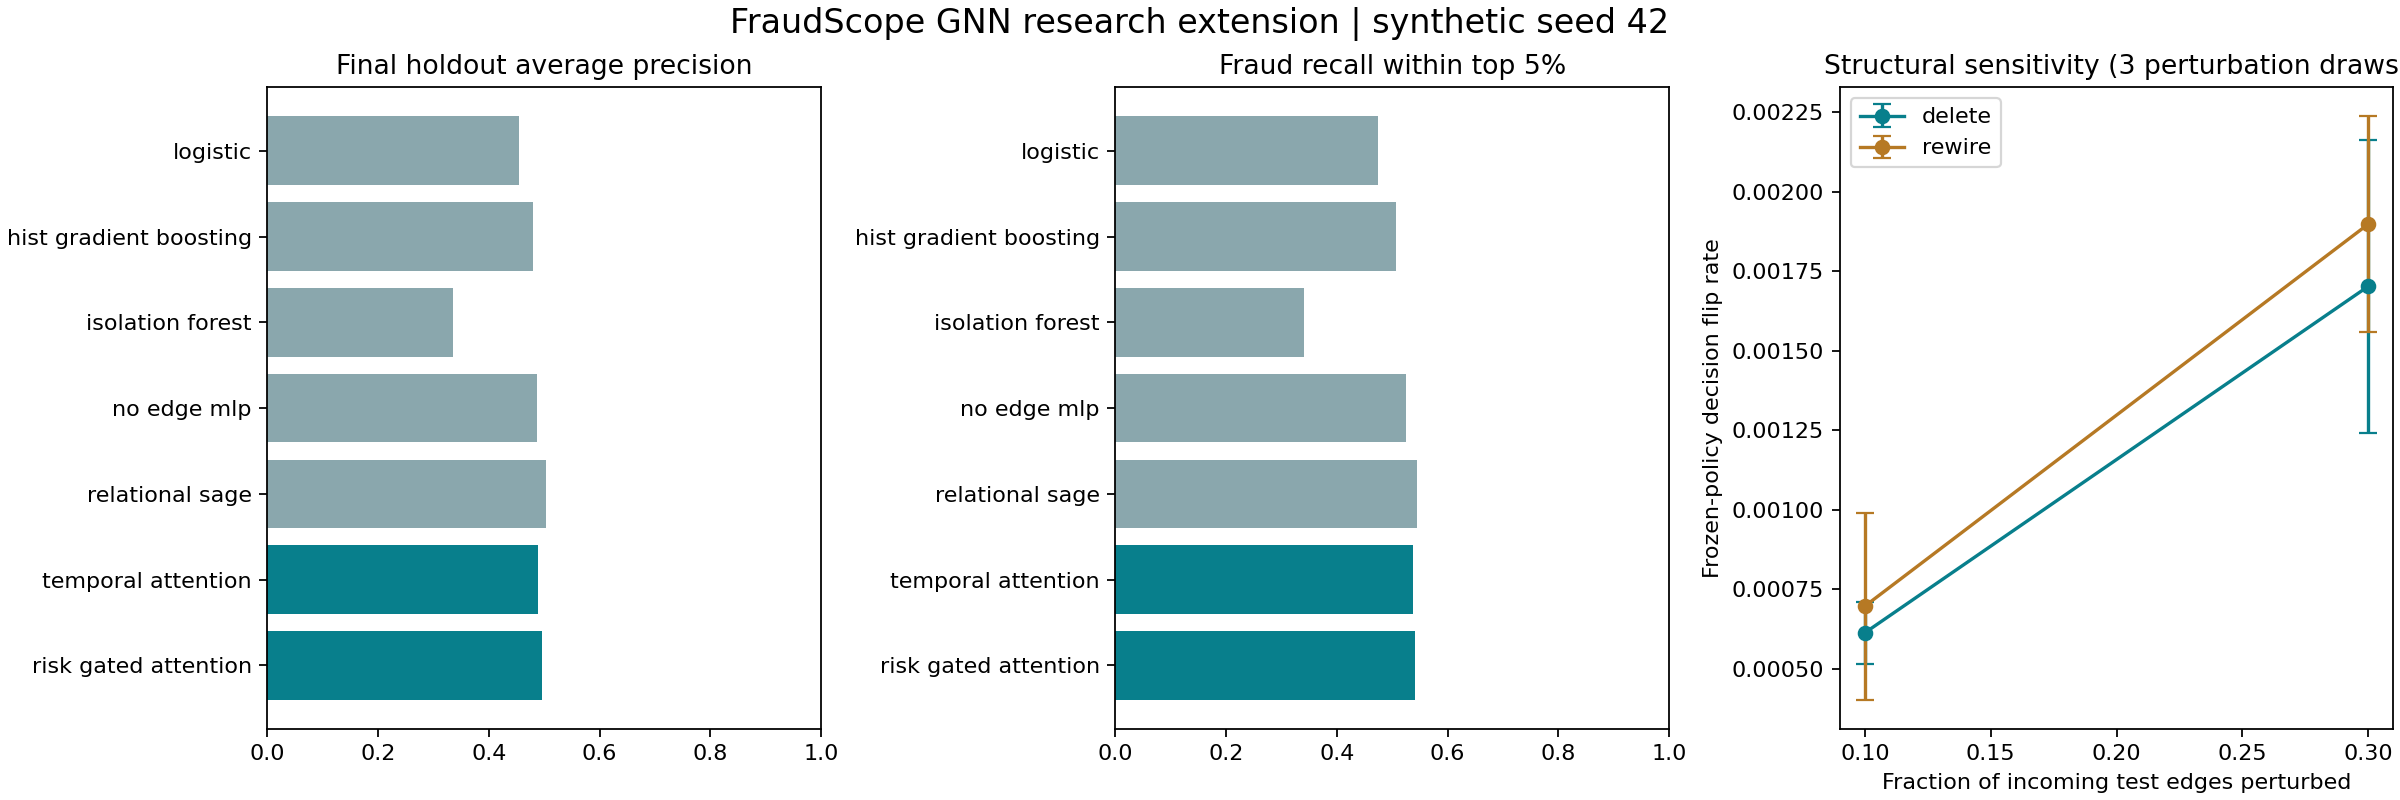

In [6]:
summary=json.loads((ROOT/"reports/gnn/multi_seed_summary.json").read_text())
display(pd.DataFrame(summary["models"])[["model","average_precision_mean","average_precision_std","recall_at_5pct_mean","recall_at_5pct_std"]])
display(pd.DataFrame(summary["selection_by_seed"]))
display(Image(filename=str(ROOT/"reports/gnn_notebook/gnn_comparison.png")))

## 6. Separate graph change from model response

We freeze the selected graph candidate, calibrator and threshold. Delete or causally rewire 10% or 30% of incoming test edges, with three draws per condition. Track raw adjacency displacement, embedding drift, score drift, threshold flips and predictive metrics. Rewiring is a synthetic integrity failure and breaks entity membership.

In [7]:
stress=pd.DataFrame(json.loads((ROOT/"reports/gnn_notebook/structural_stress.json").read_text()))
display(stress[["kind","requested_fraction","replicate","raw_relation_adjacency_frobenius_delta","mean_embedding_l2_drift","mean_absolute_score_drift","threshold_flip_rate","average_precision"]])
display(stress.groupby(["kind","requested_fraction"])[["threshold_flip_rate","mean_absolute_score_drift","average_precision"]].agg(["mean","std"]))

,kind,requested_fraction,replicate,raw_relation_adjacency_frobenius_delta,mean_embedding_l2_drift,mean_absolute_score_drift,threshold_flip_rate,average_precision
0,delete,0.1,0,35.972211,0.235924,0.000880,0.000502,0.491533
1,delete,0.1,1,35.972211,0.236713,0.000835,0.000670,0.484622
2,delete,0.1,2,35.972211,0.238363,0.000922,0.000670,0.491174
3,delete,0.3,0,62.321746,0.680757,0.002580,0.001172,0.489656
4,delete,0.3,1,62.321746,0.685144,0.002536,0.001925,0.487210
5,delete,0.3,2,62.321746,0.677914,0.002392,0.002009,0.491199
6,rewire,0.1,0,50.872389,0.262749,0.001000,0.000419,0.488398
7,rewire,0.1,1,50.872389,0.264753,0.000995,0.001005,0.484643
8,rewire,0.1,2,50.872389,0.261790,0.001004,0.000670,0.492241
9,rewire,0.3,0,88.136258,0.755201,0.003046,0.001842,0.486843


threshold_flip_rate  ... average_precision
                                         mean  ...               std
kind   requested_fraction                      ...                  
delete 0.1                           0.000614  ...          0.003891
       0.3                           0.001702  ...          0.002012
rewire 0.1                           0.000698  ...          0.003799
       0.3                           0.001898  ...          0.006641

[4 rows x 6 columns]

## 7. Replay a trained neural checkpoint

The neural file contains a state dictionary loaded with weights-only mode. The separate preprocessing/calibration objects are trusted local joblib files. This replay validates saved research predictions, not an online graph-serving path.

In [8]:
import joblib
from fraudscope.splits import temporal_split
folder=ROOT/"reports/gnn_notebook"
name=result["graph_candidate_winner"]
model=load_weights(folder/f"{name}.pt")
prep=joblib.load(folder/"preprocessing.joblib")
policy=joblib.load(folder/f"{name}_policy.joblib")
cache=np.load(folder/"causal_graph.npz")
data=tensors(prep["preprocessor"].transform(X).astype(np.float32),graph,cache["risk"])
idx,_=temporal_split(df)
raw=predict(model,data,idx["test"][:50])
replayed=policy["calibrator"].predict(raw)
saved=pd.read_csv(folder/"holdout_predictions.csv")[name].to_numpy()[:50]
assert np.allclose(replayed,saved)
print("Reloaded GNN probabilities match the saved research results.")

Reloaded GNN probabilities match the saved research results.


## 8. Why direction and signs need care

These edges encode time-respecting information flow. A reversal that makes a historical transaction see a future neighbor is invalid. Fraud labels are not permitted as positive/negative edge signs. Signed or magnetic models need real, scoring-time sign semantics and a separate experimental contract.

In [9]:
bad=build_temporal_graph(df.head(100),neighbors=8)
bad.neighbors[0,0,0]=99
try:
    bad.validate()
except ValueError as error:
    print("Expected causal-graph rejection:",error)
else:
    raise AssertionError("A future edge was incorrectly accepted")

Expected causal-graph rejection: Future or simultaneous edge rejected


## 9. Your next independent study

Use the same split to compare transaction-only features with engineered behavior and learned relational messages. Reserve a fresh final period. Then separate frozen perturbation response from matched retraining. For a defensible signed network, examine operator normalization and charge choices without assuming that earlier theorems transfer unchanged.

Read `docs/GNN_STABILITY_PROTOCOL.md`. The pilot does not establish significance, a new stability theorem, or deployment readiness. Real IEEE-CIS remains pending. HGT, TGN memory and RGH-GNN are cited as research context, not claimed reproductions.